# recursion_limit과 명시적 종료

**이 노트북에서 할 일**

1. 끝점으로 가는 엣지가 없는 그래프가 실행 한도에 닿아 멈추는 것을 봅니다.
2. 조건 함수가 `END`를 내놓게 해, 같은 한도 안에서 흐름을 끝냅니다.
3. 한도 값을 바꿔, 노드 실행 수와 한도의 경계를 출력으로 확인합니다.

**준비물** — 이 노트북은 모델을 부르지 않습니다.
모델 요청은 0번이고, API 키 없이 실행합니다.
그래서 `.env` 파일을 읽는 셀과 키를 확인하는 셀이 없습니다.
모델 답에 따라 되풀이 횟수가 달라지면, 한도에 닿는 장면을 매번 같게 볼 수 없기 때문입니다.
그래서 모델을 부르지 않고, 정해 둔 차례를 따르는 우리 노드 둘로 그래프를 만듭니다.

노트북 안 규정 딕셔너리를 읽기만 하고, 읽는 파일과 새로 쓰는 파일은 없습니다.
교재 출력을 만든 실행에서는 노트북 전체가 10초 안에 끝났습니다.

**기준 버전** — 첫 셀에서 패키지 셋을 설치합니다.
판은 langgraph 1.2.11, langchain 1.4.0, langchain-core 1.6.2입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~5절을 읽습니다.
노드 둘을 만들고, 끝나는 엣지가 없는 그래프와 조건 함수로 끝내는 그래프를 견주는 자리입니다.
6·7절은 한도 값을 바꿔 경계를 찾고 바퀴 한도와 견주는 자리이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part5/ch20-tool-node`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![왼쪽과 오른쪽에 칸 둘이 나란히 있는 그림입니다. 왼쪽 칸 Before 끝점으로 가는 엣지 없음에는 회색 가상 시작점 START에서 파란 상자 고르기 노드 pick 함수 pick_topic으로, 다시 파란 상자 찾기 노드 find 함수 find_policy로 실선이 가고, 찾기 노드에서 고르기 노드로 되돌아가는 엣지 실선이 돌아옵니다. 오른쪽 칸 After 명시적 종료에는 같은 시작점과 두 노드가 있고, 고르기 노드에서 점선 두 갈래가 나가 주제어 있음 이름표 find는 찾기 노드로, 빈 글 이름표 END는 회색 가상 끝점 END로 갑니다. 찾기 노드에서 고르기 노드로 되돌아가는 엣지 실선이 돌아오는 그림](attachment:03-1-끝나는-엣지가-다른-두-그래프.png)

왼쪽 칸이 Before, 오른쪽 칸이 After이고, 칸 안은 위에서 아래로 읽습니다.
파란 상자는 우리가 적은 노드이고, 회색은 LangGraph의 가상 시작점과 가상 끝점입니다.
왼쪽 칸에는 끝점이 없어, 고르기 노드와 찾기 노드를 오가는 길만 있습니다.
오른쪽 칸은 고르기 노드에서 점선 두 갈래가 나가고, 빈 글이면 끝점으로 갑니다.
오른쪽 칸의 상자 넷과 화살표 넷은 노트북 5절 구조 문자열과 같습니다.
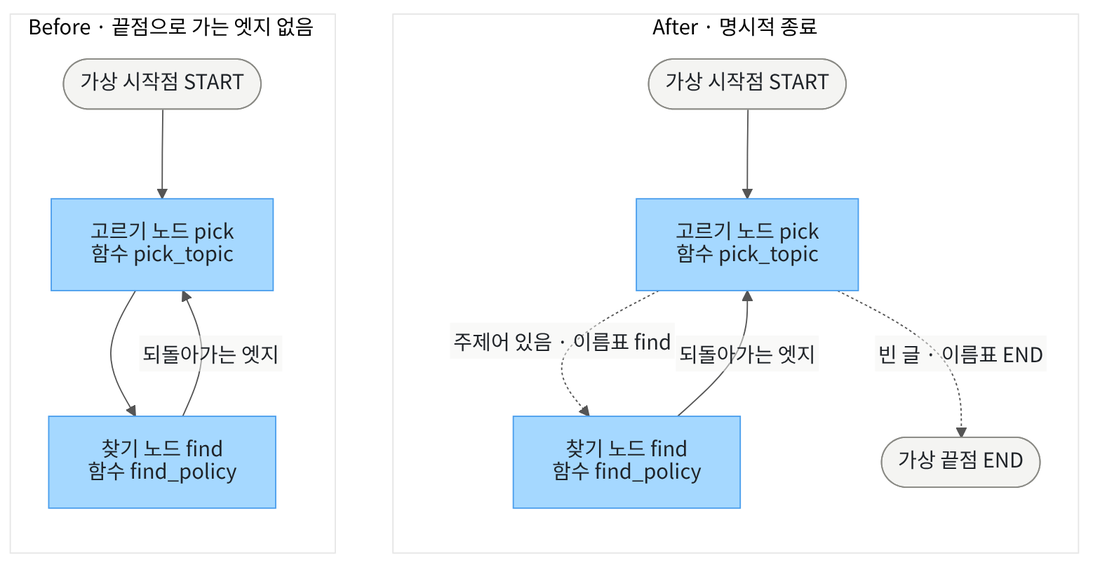

## 1. 준비

01절과 02절 그래프는 되풀이하는 횟수의 한도를 따로 정하지 않고 실행했습니다.
이 절은 그 한도와, 흐름을 끝내는 조건을 봅니다.
제목의 `recursion_limit`은 실행 한도이고, 뜻은 4절에서 풉니다.

첫 셀은 패키지 세 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langgraph==1.2.11" "langchain==1.4.0" "langchain-core==1.6.2"
from importlib.metadata import version

print("langgraph:", version("langgraph"))
print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))

Note: you may need to restart the kernel to use updated packages.
langgraph: 1.2.11
langchain: 1.4.0
langchain-core: 1.6.2


**결과 읽기** — 출력 줄 `langgraph: 1.2.11`·`langchain: 1.4.0`·`langchain-core: 1.6.2`가 보입니다.
세 판 모두 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-24에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
그래프와 도구 이름은 01절과 같고, 오류 이름 하나를 더 가져옵니다.
모델을 부르지 않으니 모델과 메시지 이름은 가져오지 않습니다.

In [2]:
# Ch 13 그래프 이름과 Ch 19 도구 이름에, 한도를 넘었을 때 나는 오류 이름 하나를 더해 가져옵니다
import operator
from typing import Annotated
from typing_extensions import TypedDict

from langchain.tools import tool
from langgraph.graph import END, START, StateGraph
# 실행 한도를 넘으면 그래프가 내는 오류의 이름입니다
from langgraph.errors import GraphRecursionError

print("이 절에서 새로 가져온 이름:", "GraphRecursionError")

이 절에서 새로 가져온 이름: GraphRecursionError


**결과 읽기** — 출력 줄 `이 절에서 새로 가져온 이름: GraphRecursionError`가 보입니다.
이 이름은 그래프가 실행 한도를 넘었을 때 내는 오류의 이름입니다.
4절에서 이 오류를 받아 출력합니다.

모델을 부르지 않는 절이라, Ch 13 01~06절처럼 API 키 셀도 없습니다.

## 2. 규정 자료와 도구

자료와 도구는 01절과 같은 코드입니다.
다음 셀은 01절처럼 주제어를 키, 규정 글을 값으로 둔 딕셔너리를 만듭니다.

In [3]:
# 교육센터 자료실 규정 셋을, 주제어를 키로 한 딕셔너리에 담습니다(도구가 읽기만 하는 자료)
POLICIES = {
    "대출": "일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.",
    "운영": "평일은 09:00~20:00, 토요일은 10:00~17:00에 운영합니다.",
    "연체": "연체한 일수만큼 새 대출이 제한됩니다.",
}
topics = list(POLICIES.keys())
print("규정 주제어:", topics)

규정 주제어: ['대출', '운영', '연체']


**결과 읽기** — 출력 줄 `규정 주제어: ['대출', '운영', '연체']`로 키 셋을 확인합니다.
이 셀은 01절 셀과 글자까지 같습니다.

다음 셀은 01절과 같은 도구 `lookup_policy`를 만듭니다.
코드는 01절과 같고, 오류를 내는 줄 위 주석 한 줄만 이 절에 맞게 고쳤습니다.

In [4]:
# 주제어 하나로 규정 글 하나를 찾는 도구를 만듭니다(맨 @tool 줄 — Ch 19 01절)
@tool
def lookup_policy(topic: str):
    """교육센터 자료실 규정 하나를 주제어로 찾습니다. topic에는 대출, 운영, 연체 가운데 하나를 넣습니다."""
    # 딕셔너리에 없는 주제어면 오류를 냅니다(02절에서 본 ValueError입니다)
    if topic not in POLICIES:
        raise ValueError("지원하지 않는 주제: " + topic)
    return POLICIES[topic]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 절에서는 노드 하나가 이 도구를 코드로 직접 부릅니다.
Ch 19 01절처럼 메서드 `.invoke`에 인자 딕셔너리를 넣는 모양입니다.

다음 셀은 빈 글을 주제어로 도구를 불러 봅니다.
실행 전에 예상해 봅니다.
빈 글도 글자라서 입력 검사는 지나고, 몸통에서 02절의 `ValueError`가 날 것입니다.
이 셀만 그 오류를 받아 출력하고, 셀은 끝까지 갑니다.

In [5]:
# 빈 글을 주제어로 도구를 불러 봅니다(이 셀만 오류를 받아 출력합니다)
try:
    lookup_policy.invoke({"topic": ""})
except ValueError as error:
    print("받은 오류:", type(error).__name__)
    print("오류 글:", error)

받은 오류: ValueError
오류 글: 지원하지 않는 주제: 


**결과 읽기** — 출력 줄 `받은 오류: ValueError`처럼 몸통에서 오류가 났습니다.
라벨 `오류 글:` 뒤 `지원하지 않는 주제:` 다음이 비어 있는 것은, 주제어가 빈 글이기 때문입니다.
그래서 3절의 찾기 노드는 주제어가 빈 글이면 도구를 부르지 않습니다.

## 3. 상태 형식과 노드 둘

이 절의 그래프는 01절 그래프와 같은 모양입니다.
노드 둘을 되돌아가는 엣지로 잇고, 한 노드 뒤에서 갈 곳을 고릅니다.
다만 모델 노드와 도구 실행 노드 대신, 우리가 적은 평범한 노드 둘을 씁니다.
한 노드는 다음에 찾을 주제어를 고르고, 다른 노드는 도구로 규정 글을 찾습니다.

다음 셀은 상태 형식입니다.
칸 `topics`는 찾을 주제어 목록, 칸 `next_topic`은 다음에 찾을 주제어입니다.
칸 `found`는 찾은 규정 글, 칸 `trace`는 실행 흔적입니다.
뒤의 두 칸에는 Ch 13 02절처럼 이어 붙이기 규칙 `operator.add`를 적습니다.
칸 구성이 01절 `AgentState`와 달라서, Ch 13 약속대로 새 이름 `TopicState`를 붙입니다.

In [6]:
# 찾을 주제어·다음 주제어·찾은 규정·실행 흔적 칸을 둔 상태 형식을 만듭니다(뒤의 두 칸은 Ch 13 02절 규칙)
class TopicState(TypedDict):
    topics: list[str]
    next_topic: str
    found: Annotated[list[str], operator.add]
    trace: Annotated[list[str], operator.add]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
칸 `topics`와 `next_topic`은 규칙이 없어, 노드가 낸 값으로 덮어씁니다.
칸 `found`와 `trace`는 노드가 낸 목록을 뒤에 이어 붙입니다.

다음 셀은 다음에 찾을 주제어를 고르는 노드 함수입니다.
찾은 규정 수를 보고, 아직 찾지 않은 주제어가 남았으면 목록에서 그 차례의 주제어를 적습니다.
모두 찾았으면 빈 글을 적습니다.
이 노드는 정해 둔 차례를 따르는 우리 노드이고, 01절 모델 노드처럼 되돌아가는 엣지가 돌아오는 자리에 둡니다.

In [7]:
# 찾은 규정 수를 보고, 다음에 찾을 주제어 하나를 칸 next_topic에 적습니다
def pick_topic(state):
    index = len(state["found"])
    # 아직 찾지 않은 주제어가 남았으면 그 차례의 주제어를, 모두 찾았으면 빈 글을 적습니다
    if index < len(state["topics"]):
        return {"next_topic": state["topics"][index], "trace": ["pick"]}
    return {"next_topic": "", "trace": ["pick"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `pick_topic`은 칸 `next_topic`과 실행 흔적 `"pick"`만 냅니다.
그래프에는 이름 `"pick"`으로 등록하고, 이 절에서는 고르기 노드라고 부릅니다.

다음 셀은 이 노드를 그래프 없이 직접 불러 봅니다.
Ch 13 03절에서 조건 함수를 직접 불렀던 것처럼, 손으로 만든 상태 둘을 넣습니다.
하나는 규정을 아직 찾지 않은 상태, 다른 하나는 대출 규정을 이미 찾은 상태입니다.

In [8]:
# 고르기 노드를 그래프 없이 직접 불러, 찾은 규정 수에 따라 무엇을 적는지 봅니다
loan_state = {"topics": ["대출"], "next_topic": "", "found": [], "trace": []}
done_state = {"topics": ["대출"], "next_topic": "대출", "found": [POLICIES["대출"]], "trace": ["pick", "find"]}
print("찾은 규정이 없을 때:", pick_topic(loan_state))
print("하나를 찾은 뒤:", pick_topic(done_state))

찾은 규정이 없을 때: {'next_topic': '대출', 'trace': ['pick']}
하나를 찾은 뒤: {'next_topic': '', 'trace': ['pick']}


**결과 읽기** — 출력 줄 `찾은 규정이 없을 때: {'next_topic': '대출', 'trace': ['pick']}`입니다.
출력 줄 `하나를 찾은 뒤: {'next_topic': '', 'trace': ['pick']}`로, 모두 찾으면 빈 글을 적습니다.
첫 상태 `loan_state`는 01절 7절 대출 질문처럼 주제어가 대출 하나인 상태입니다.
4절부터 그래프의 첫 상태로 이 값을 그대로 씁니다.

다음 셀은 칸 `next_topic`의 주제어로 규정 글을 찾는 노드 함수입니다.
주제어가 빈 글이면 2절처럼 오류가 나므로, 도구를 부르지 않고 실행 흔적만 남깁니다.
이 노드는 01절 도구 실행 노드 자리에 둡니다.

In [9]:
# 칸 next_topic의 주제어로 도구를 불러, 찾은 규정 글 하나를 냅니다
def find_policy(state):
    topic = state["next_topic"]
    # 빈 글이면 도구를 부르지 않습니다(2절처럼 ValueError가 나기 때문입니다)
    if topic == "":
        return {"trace": ["find"]}
    policy = lookup_policy.invoke({"topic": topic})
    return {"found": [policy], "trace": ["find"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `find_policy`는 그래프에 이름 `"find"`로 등록하고, 이 절에서는 찾기 노드라고 부릅니다.
주제어가 있으면 칸 `found`에 규정 글 하나를, 없으면 실행 흔적만 냅니다.

다음 셀은 이 노드도 그래프 없이 직접 불러 봅니다.
주제어가 대출인 상태와 빈 글인 상태를 손으로 만들어 넣습니다.

In [10]:
# 찾기 노드를 그래프 없이 직접 불러, 주제어가 있을 때와 빈 글일 때를 봅니다
ask_state = {"topics": ["대출"], "next_topic": "대출", "found": [], "trace": ["pick"]}
empty_state = {"topics": ["대출"], "next_topic": "", "found": [POLICIES["대출"]], "trace": ["pick", "find", "pick"]}
print("주제어가 대출일 때:", find_policy(ask_state))
print("빈 글일 때:", find_policy(empty_state))

주제어가 대출일 때: {'found': ['일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.'], 'trace': ['find']}
빈 글일 때: {'trace': ['find']}


**결과 읽기** — 주제어가 대출일 때 칸 `found`에 `일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.`가 담겼습니다.
출력 줄 `빈 글일 때: {'trace': ['find']}`로, 빈 글이면 실행 흔적만 냅니다.
두 노드 모두 모델을 부르지 않아, 같은 상태를 넣으면 매번 같은 값을 냅니다.

## 4. 끝나는 엣지 없이 실행하기 (Before)

먼저 01절처럼 두 노드를 되돌아가는 엣지로 잇습니다.
이번에는 고르기 노드 다음을 늘 찾기 노드로 잇고, 끝점 `END`로 가는 엣지는 적지 않습니다.
고르기 노드는 주제어를 다 찾으면 빈 글을 적지만, 그래프는 그 칸을 보고 멈추지 않습니다.
그래프가 어디로 갈지는 노드 안의 코드가 아니라 엣지가 정하기 때문입니다.
다음 셀은 이 그래프를 만들고, 적어 둔 엣지 수를 봅니다.

In [11]:
# Before: 고르기 노드 다음을 늘 찾기 노드로 잇고, 끝점 END로 가는 엣지는 적지 않습니다
before_builder = StateGraph(TopicState)
before_builder.add_node("pick", pick_topic)
before_builder.add_node("find", find_policy)
before_builder.add_edge(START, "pick")
before_builder.add_edge("pick", "find")
before_builder.add_edge("find", "pick")
before_graph = before_builder.compile()
print("고정 엣지로 적은 수:", len(before_builder.edges))
print("조건부 엣지를 적은 노드 수:", len(before_builder.branches))

고정 엣지로 적은 수: 3
조건부 엣지를 적은 노드 수: 0


**결과 읽기** — 출력 줄 `고정 엣지로 적은 수: 3`은 시작 엣지·`pick → find`·`find → pick`입니다.
출력 줄 `조건부 엣지를 적은 노드 수: 0`으로, 갈 곳을 고르는 엣지는 없습니다.
속성 `branches`에는 조건부 엣지를 적은 노드가 들어가는데, 이 그래프는 비어 있습니다.
엣지 셋 가운데 끝점으로 가는 것은 없고, `find → pick`이 01절의 되돌아가는 엣지입니다.

다음 셀은 01·02절처럼 한도를 따로 적지 않고, 3절의 첫 상태로 이 그래프를 실행합니다.
실행 전에 예상해 봅니다.
대출 규정은 찾기 노드를 한 번 지나면 찾지만, 그래프는 끝나지 않을 것입니다.
이 셀만 올라온 오류를 받아 출력하고, 셀은 끝까지 갑니다.

In [12]:
# Before 그래프를 대출 주제어 하나로, 한도를 적지 않고 실행합니다(이 셀만 올라온 오류를 받아 출력합니다)
try:
    before_graph.invoke(loan_state)
except GraphRecursionError as error:
    print("받은 오류:", type(error).__name__)
    print("오류 글:")
    print(error)

받은 오류: GraphRecursionError
오류 글:
Recursion limit of 10007 reached without hitting a stop condition. You can increase the limit by setting the `recursion_limit` config key.
For troubleshooting, visit: https://docs.langchain.com/oss/python/langgraph/errors/GRAPH_RECURSION_LIMIT


**결과 읽기** — 출력 줄 `받은 오류: GraphRecursionError`처럼 그래프가 스스로 멈추지 않았습니다.
오류 글 첫 줄 `Recursion limit of 10007 reached without hitting a stop condition.`을 봅니다.
끝나는 조건에 닿지 못한 채 한도 10007에 닿았다는 뜻입니다.
한도를 적지 않으면 설치한 langgraph의 기본 한도가 쓰이고, 이 판에서는 그 값이 10007입니다.
오류 글 둘째 줄의 주소는 이 오류를 설명하는 공식 문서입니다.

메서드 `invoke`가 결과를 내놓지 않아, 찾은 대출 규정 글도 이 셀에서는 받지 못했습니다.
노트북 밖에서 노드가 실행될 때마다 따로 세어 보니, 두 노드를 합쳐 10007번 실행했습니다.
01절 그래프에서 모델이 요청을 끝없이 보냈다면, 셈으로는 모델 요청이 5천 번 넘게 나갑니다.
그 흐름은 이번에 실행하지 않았습니다.
이것이 Before의 결함입니다.

그래서 한도를 우리가 적어 줍니다.
그래프를 실행할 때 메서드 `invoke`의 둘째 인자로 설정 딕셔너리를 넘깁니다.
설정 딕셔너리는 상태가 아니라, 실행하는 방법을 적은 딕셔너리입니다.
Ch 13 07절의 설정 칸은 상태 안의 칸이었지만, 설정 딕셔너리는 상태 밖에서 넘깁니다.
키 `"recursion_limit"`에 적은 수가 실행 한도입니다.

실행 한도는 그래프가 한 번 실행에서 진행할 수 있는 단계 수의 한도입니다.
단계는 그래프가 실행할 노드를 골라 한 번 실행하는 차례입니다.
이 절 그래프는 단계마다 노드 하나를 실행합니다.
자료실로 치면 상자가 한 층을 들를 때마다 한 칸씩 차는 계수기의 칸 수입니다.

다음 셀은 한도 10을 적은 설정 딕셔너리로 같은 Before 그래프를 다시 실행합니다.
한도 10은 흐름을 보여 주려고 이 절에서 정한 값입니다.
이 셀도 올라온 오류만 받아 출력합니다.

In [13]:
# 설정 딕셔너리에 실행 한도 10을 적어, Before 그래프를 다시 실행합니다(이 셀도 오류를 받아 출력합니다)
limit_config = {"recursion_limit": 10}
print("설정 딕셔너리:", limit_config)
try:
    # 둘째 인자로 넘긴 설정 딕셔너리는 상태에 들어가지 않고, 그래프가 실행 단계를 셀 때 씁니다
    before_graph.invoke(loan_state, limit_config)
except GraphRecursionError as error:
    print("받은 오류:", type(error).__name__)
    print("오류 글:")
    print(error)

설정 딕셔너리: {'recursion_limit': 10}
받은 오류: GraphRecursionError
오류 글:
Recursion limit of 10 reached without hitting a stop condition. You can increase the limit by setting the `recursion_limit` config key.
For troubleshooting, visit: https://docs.langchain.com/oss/python/langgraph/errors/GRAPH_RECURSION_LIMIT


**결과 읽기** — 출력 줄 `설정 딕셔너리: {'recursion_limit': 10}`입니다.
오류 글 첫 줄이 `Recursion limit of 10 reached without hitting a stop condition.`으로 바뀌었습니다.
한도를 적자 단계 10에서 멈췄지만, 결과를 받지 못한 것은 앞 셀과 같습니다.
실행 한도는 끝나지 않는 되풀이를 끊어 줄 뿐, 흐름을 제대로 끝내 주지는 않습니다.

노트북 밖에서 같은 그래프를 한도 1~5와 10으로 실행해 노드 실행 수를 세었습니다.
한도가 N이면 노드를 N번 실행한 뒤 멈췄습니다.

## 5. 조건 함수로 흐름 끝내기 (After)

이제 결함을 고칩니다.
고르기 노드 뒤에 조건 함수를 두어, 칸 `next_topic`이 빈 글이면 `END`를 내놓게 합니다.
흐름을 끝낼 때를 이렇게 조건 함수에 적어 두는 것을, 이 절에서는 명시적 종료라고 부릅니다.
자료실로 치면 창구 층에 받침을 달아, 찾을 쪽지가 없으면 상자가 거기서 서게 하는 일입니다.

01절 도구 조건 함수는 요청이 없는 응답에서 `END`를 냈습니다.
이 절의 조건 함수는 빈 글에서 `END`를 냅니다.
Ch 13 03절처럼 여러 줄 `if`로 적고, 조건 함수는 노드로 등록하지 않습니다.

In [14]:
# 칸 next_topic을 보고, 찾을 주제어가 있으면 이름표 "find"를, 빈 글이면 END를 내놓습니다
def next_or_end(state):
    if state["next_topic"] == "":
        return END
    return "find"

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `next_or_end`는 칸을 읽기만 하고, 상태를 바꾸지 않습니다.
끝 쪽 이름표는 글자 대신 상수 `END`로 적었습니다.

다음 셀은 이 조건 함수를 그래프 없이 직접 불러 봅니다.
3절에서 만든 상태 둘, 곧 주제어가 대출인 상태와 빈 글인 상태를 넣습니다.

In [15]:
# 조건 함수를 그래프 없이 직접 불러, 3절의 두 상태에 어떤 이름표를 내놓는지 봅니다
ask_label = next_or_end(ask_state)
empty_label = next_or_end(empty_state)
print("주제어가 있을 때의 이름표:", ask_label)
print("빈 글일 때의 이름표:", empty_label)
print("END와 같은가:", empty_label == END)

주제어가 있을 때의 이름표: find
빈 글일 때의 이름표: __end__
END와 같은가: True


**결과 읽기** — 출력 줄 `주제어가 있을 때의 이름표: find`와 `빈 글일 때의 이름표: __end__`입니다.
출력 줄 `END와 같은가: True`로, 글자 `__end__`는 상수 `END`의 값입니다.
01절에서 도구 조건 함수가 내놓은 이름표와 같은 모양입니다.

다음 셀은 이름표 둘을 실제로 갈 곳에 잇는 이름표 표입니다.

In [16]:
# 조건 함수의 이름표 둘을 실제로 갈 곳에 잇는 이름표 표를 만듭니다(Ch 13 03절)
path_map = {"find": "find", END: END}
print("이름표와 갈 곳을 이은 표:")
for label in path_map:
    print(label, "->", path_map[label])

이름표와 갈 곳을 이은 표:
find -> find
__end__ -> __end__


**결과 읽기** — 라벨 줄 아래 두 줄 `find -> find`와 `__end__ -> __end__`입니다.
01절 이름표 표와 모양이 같고, 이름표 하나만 `"find"`로 바뀌었습니다.

다음 셀은 After 그래프를 만듭니다.
Before 그래프와 다른 곳은 고르기 노드에서 나가는 엣지 한 줄뿐입니다.
고정 엣지 `pick → find` 대신, 조건 함수와 이름표 표로 조건부 엣지를 적습니다.

In [17]:
# After: 고르기 노드에서 나가는 엣지만 조건부 엣지로 바꿔 그래프를 만듭니다
after_builder = StateGraph(TopicState)
after_builder.add_node("pick", pick_topic)
after_builder.add_node("find", find_policy)
after_builder.add_edge(START, "pick")
after_builder.add_conditional_edges("pick", next_or_end, path_map)
after_builder.add_edge("find", "pick")
after_graph = after_builder.compile()
print("고정 엣지로 적은 수:", len(after_builder.edges))
print("조건부 엣지를 적은 노드 수:", len(after_builder.branches))

고정 엣지로 적은 수: 2
조건부 엣지를 적은 노드 수: 1


**결과 읽기** — 출력 줄 `고정 엣지로 적은 수: 2`와 `조건부 엣지를 적은 노드 수: 1`입니다.
고정 엣지는 시작 엣지와 되돌아가는 엣지 `find → pick`만 남았습니다.
고르기 노드에서 나가는 엣지가 조건부 엣지 하나로 바뀌었습니다.

다음 셀은 그래프가 스스로 그린 구조 문자열을 봅니다.

In [18]:
# 컴파일한 After 그래프가 스스로 그린 구조 문자열을 받아 옵니다(Ch 13 01절)
after_structure = after_graph.get_graph().draw_mermaid()
print("그래프가 그린 구조:")
print(after_structure)

그래프가 그린 구조:
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	pick(pick)
	find(find)
	__end__([<p>__end__</p>]):::last
	__start__ --> pick;
	find --> pick;
	pick -.-> __end__;
	pick -.-> find;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



**결과 읽기** — 라벨 줄 `그래프가 그린 구조:` 아래 화살표 줄 넷을 봅니다.
줄 `__start__ --> pick;`이 시작 엣지이고, 줄 `find --> pick;`이 되돌아가는 엣지입니다.
줄 `pick -.-> __end__;`와 `pick -.-> find;`가 조건부 엣지의 두 갈래입니다.
이제 그래프에는 끝점으로 가는 갈래가 있습니다.

다음 셀은 3절의 첫 상태와 4절의 설정 딕셔너리(한도 10)로 After 그래프를 실행합니다.
실행 전에 예상해 봅니다.
고르기·찾기·고르기 차례로 지나고, 둘째 고르기 뒤 조건 함수가 `END`를 내놓을 것입니다.

In [19]:
# After 그래프를 3절의 첫 상태와 4절의 설정 딕셔너리(한도 10)로 실행합니다
after_result = after_graph.invoke(loan_state, limit_config)
print("실행 흔적 칸:", after_result["trace"])
print("찾은 규정 수:", len(after_result["found"]))
print("찾은 규정:", after_result["found"][0])
print("칸 next_topic이 빈 글인가:", after_result["next_topic"] == "")

실행 흔적 칸: ['pick', 'find', 'pick']
찾은 규정 수: 1
찾은 규정: 일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.
칸 next_topic이 빈 글인가: True


**결과 읽기** — 출력 줄 `실행 흔적 칸: ['pick', 'find', 'pick']`으로 노드를 세 번 지나고 끝났습니다.
출력 줄 `찾은 규정 수: 1`과 규정 글로, Before가 받지 못한 결과를 이번에는 받았습니다.
출력 줄 `칸 next_topic이 빈 글인가: True`는 둘째 고르기 노드가 빈 글을 적었다는 뜻입니다.
조건 함수가 그 빈 글을 보고 `END`를 내놓아, 한도 10에 닿기 전에 끝났습니다.

다음 셀은 노드 실행 수를 세고, 매번 같아야 하는 값을 `assert`로 확인합니다.

In [20]:
# 노드 실행 수를 세고, 모델 없이 매번 같아야 하는 값을 확인합니다
after_runs = len(after_result["trace"])
print("노드 실행 수:", after_runs)
# 두 노드는 모델을 부르지 않으므로, 차례와 찾은 규정 수가 매번 같아야 합니다
assert after_result["trace"] == ["pick", "find", "pick"], "고르기·찾기·고르기 차례로 끝나야 합니다"
assert len(after_result["found"]) == 1, "대출 규정 글 하나를 찾아야 합니다"

노드 실행 수: 3


**결과 읽기** — 출력 줄 `노드 실행 수: 3`입니다.
이 그래프는 단계마다 노드 하나를 실행하므로, 단계도 3번입니다.
두 `assert`는 모델이 아니라 우리 코드가 정하는 값에 걸었습니다.

## 6. 값 바꿔 보기 · 실행 한도

바꿀 값은 설정 딕셔너리의 한도입니다.
대출 흐름은 노드를 3번 실행하고 끝났습니다.
그렇다면 한도가 3이면 통과할까요?
한도를 3과 4로 바꿔 같은 흐름을 실행해 봅니다.

다음 셀은 한도 목록의 값마다 그래프를 실행해, 통과했는지 출력하는 함수입니다.
통과하면 노드 실행 수를, 한도에 닿으면 받은 오류 이름을 출력합니다.

In [21]:
# 그래프 하나와 첫 상태 하나를 받아, 한도 목록의 값마다 실행해 통과했는지 출력합니다
def try_limits(graph, state, limits):
    for limit in limits:
        config = {"recursion_limit": limit}
        # 한도에 닿으면 그 한도에서 받은 오류 이름만 출력하고, 다음 한도로 넘어갑니다
        try:
            result = graph.invoke(state, config)
            print("한도", limit, "| 통과 | 노드 실행 수:", len(result["trace"]))
        except GraphRecursionError as error:
            print("한도", limit, "| 받은 오류:", type(error).__name__)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `try_limits`는 한도마다 설정 딕셔너리를 새로 만들어 넘깁니다.
받은 오류는 Ch 2 05절처럼 그 한도에서만 받아 출력하고, 다음 한도로 넘어갑니다.

다음 셀은 대출 흐름을 한도 3과 4로 실행합니다.
실행 전에 예상해 봅니다.
노드 실행 수가 3이니, 한도 3이면 딱 맞게 통과할 것처럼 보입니다.

In [22]:
# 바꿀 값: 한도를 3과 4로 바꿔, 대출 흐름을 After 그래프로 실행합니다
limits = [3, 4]
try_limits(after_graph, loan_state, limits)

한도 3 | 받은 오류: GraphRecursionError
한도 4 | 통과 | 노드 실행 수: 3


**결과 읽기** — 출력 줄 `한도 3 | 받은 오류: GraphRecursionError`로, 한도 3에서는 통과하지 못했습니다.
출력 줄 `한도 4 | 통과 | 노드 실행 수: 3`으로, 한도 4에서는 통과했습니다.
노드 실행 수와 같은 한도로는 모자라고, 하나 더 커야 했습니다.

설치한 langgraph 1.2.11 소스에서는 단계를 시작할 때마다 먼저 한도를 봅니다.
그다음에 실행할 노드가 남았는지 보고, 남은 노드가 없으면 끝냅니다.
그래서 마지막 노드 뒤, 남은 노드가 없는지 확인하는 차례까지 한도 안에 들어야 합니다.

다음 셀은 주제어를 01절 9절 질문처럼 운영과 연체 둘로 바꿔, 한도 10으로 실행합니다.
실행 전에 예상해 봅니다.
고르기와 찾기를 두 번 오간 뒤 고르기에서 끝나, 노드 실행이 5번일 것입니다.

In [23]:
# 바꿀 값 둘째: 주제어를 운영과 연체 둘로 바꾼 첫 상태를, 한도 10으로 실행합니다
two_state = {"topics": ["운영", "연체"], "next_topic": "", "found": [], "trace": []}
two_result = after_graph.invoke(two_state, limit_config)
print("실행 흔적 칸:", two_result["trace"])
print("찾은 규정 수:", len(two_result["found"]))

실행 흔적 칸: ['pick', 'find', 'pick', 'find', 'pick']
찾은 규정 수: 2


**결과 읽기** — 출력 줄 `실행 흔적 칸: ['pick', 'find', 'pick', 'find', 'pick']`으로 노드 실행은 5번입니다.
출력 줄 `찾은 규정 수: 2`로 운영과 연체 규정을 모두 찾았습니다.

다음 셀은 이 흐름을 한도 5와 6으로 실행합니다.
실행 전에 예상해 봅니다.
앞의 규칙대로라면 한도 5에서는 멈추고, 한도 6에서 통과할 것입니다.

In [24]:
# 같은 두 주제어 흐름을 한도 5와 6으로 실행해, 통과하는 한도를 봅니다
limits = [5, 6]
try_limits(after_graph, two_state, limits)

한도 5 | 받은 오류: GraphRecursionError
한도 6 | 통과 | 노드 실행 수: 5


**결과 읽기** — 출력 줄 `한도 5 | 받은 오류: GraphRecursionError`와 `한도 6 | 통과 | 노드 실행 수: 5`입니다.
노드를 3번 실행하는 흐름은 한도 4에서, 5번 실행하는 흐름은 한도 6에서 통과했습니다.
이 절 두 흐름에서는 노드 실행 수에 하나를 더한 한도부터 통과했습니다.

## 7. 바퀴 한도와 실행 한도

Ch 19 05절 함수 `ask_until_answer`에도 한도가 있었습니다.
바퀴 한도 `turn_limit`은 우리가 쓴 `for` 루프가 도는 바퀴 수의 한도였습니다.
그 함수는 바퀴마다 모델 요청을 한 번 보냈으니, 바퀴 한도는 모델 요청 수의 한도입니다.
실행 한도 `recursion_limit`은 그래프가 센 단계 수의 한도라, 세는 것이 다릅니다.

다음 셀은 이 절 두 흐름에서 고르기 노드를 지난 수와 노드 실행 수를 나란히 봅니다.
고르기 노드는 01절 모델 노드 자리라, 고르기 노드를 지난 수가 01절의 바퀴 수에 해당합니다.

In [25]:
# 두 흐름에서 고르기 노드를 지난 수(01절 말로 바퀴 수)와 노드 실행 수를 나란히 봅니다
loan_trace = after_result["trace"]
two_trace = two_result["trace"]
print("대출 | 고르기 노드를 지난 수:", loan_trace.count("pick"), "| 노드 실행 수:", len(loan_trace))
print("운영·연체 | 고르기 노드를 지난 수:", two_trace.count("pick"), "| 노드 실행 수:", len(two_trace))

대출 | 고르기 노드를 지난 수: 2 | 노드 실행 수: 3
운영·연체 | 고르기 노드를 지난 수: 3 | 노드 실행 수: 5


**결과 읽기** — 출력 줄 `대출 | 고르기 노드를 지난 수: 2 | 노드 실행 수: 3`입니다.
출력 줄 `운영·연체 | 고르기 노드를 지난 수: 3 | 노드 실행 수: 5`입니다.
바퀴로 세면 2번과 3번이지만, 실행 한도는 3번과 5번을 셉니다.

01절 대출 흐름도 모델 노드 두 번과 도구 실행 노드 한 번, 노드 실행 3번이었습니다.
셈으로는 01절 그래프도 한도 4부터 통과하지만, 모델이 낀 흐름에서는 이번에 실행하지 않았습니다.
그래서 바퀴 한도 값을 실행 한도에 그대로 옮겨 적지 않습니다.

## 정리

1. 끝점으로 가는 엣지가 없는 그래프는 규정을 다 찾은 뒤에도 되풀이하다, 실행 한도에서 멈췄습니다.
2. 조건 함수가 빈 글에서 `END`를 내놓게 하자, 같은 한도 10 안에서 노드 3번으로 끝났습니다.
3. 실행 한도는 노드 실행 단계를 세고, 두 흐름 모두 노드 실행 수보다 하나 큰 한도에서 통과했습니다.

04절에서는 코드의 `if`로 도구를 고르는 흐름과, 모델이 도구를 고르는 흐름을 견줍니다.